# Neighborhood Expression PCA Benchmarking 

- Creators: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 30.06.2025
- Date of Last Modification: 05.04.2026 (by Sebastian Birk (sb75@sanger.ac.uk)

- Run this notebook in the nichecompass uv environment, installable from ```../../envs/nichecompass.sh```

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [69]:
import os
import random
import warnings

import anndata as ad
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import seaborn as sns
import sklearn.metrics as skm
import squidpy as sq
from matplotlib import gridspec
from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [4]:
from analysis_utils import *

### 1.2 Configure Paths

In [5]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.3 Define Config

In [30]:
method = 'neigh_expr_pca'

# General params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
label_keys = [niche_key]
species = 'mouse'
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'
batch_key_new = 'batch_new'
n_pcs = None

# Neighborhood expression PCA params
emb_key = 'X_pca'
n_pca_pcs = 20

# Clustering params
latent_leiden_resolution = 0.7

### 1.4 Run Notebook Setup

In [7]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [8]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [9]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

pd.options.future.infer_string = False

In [10]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

/tmp/ipykernel_3504031/3043166597.py:3: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(


In [11]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}', exist_ok=True)

### 1.5 Define Functions

In [12]:
def make_large_cmap(n):
    base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"
    return [mcolors.to_hex(base(i)) for i in range(n)]

In [70]:
def mmd_comparable(adata, emb_key, batch_key, n_sub=2000, n_sigma=1000):
    # Normalize to zero mean, unit variance
    X = StandardScaler().fit_transform(adata.obsm[emb_key])
    
    # Compute sigma on normalized data
    idx = np.random.choice(len(X), min(n_sigma, len(X)), replace=False)
    sub = X[idx]
    dists = np.linalg.norm(sub[:, None] - sub[None, :], axis=2)
    sigma = np.median(dists[dists > 0])
    
    # Split by batch
    batches = adata.obs[batch_key].unique()
    mask0 = adata.obs[batch_key] == batches[0]
    mask1 = adata.obs[batch_key] == batches[1]
    b0, b1 = X[mask0], X[mask1]
    
    idx0 = np.random.choice(len(b0), min(n_sub, len(b0)), replace=False)
    idx1 = np.random.choice(len(b1), min(n_sub, len(b1)), replace=False)
    
    def rbf(A, B):
        d = np.linalg.norm(A[:, None] - B[None, :], axis=2)
        return np.exp(-d**2 / (2 * sigma**2))
    
    b0s, b1s = b0[idx0], b1[idx1]
    return rbf(b0s, b0s).mean() + rbf(b1s, b1s).mean() - 2 * rbf(b0s, b1s).mean()

In [14]:
def _combine_neighbor_graphs(adata: ad.AnnData,
                             n_neighs: int | None,
                             radius: float | None,
                             delaunay: bool,
                             include_self_loop: bool,
                             ) -> ad.AnnData:
    """
    Helper function to combine neighbor graphs computed using different
    methods.
    """
    if n_neighs is not None:
        # Compute knn spatial neighborhood graph
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                n_neighs=n_neighs,
                                set_diag=include_self_loop,
                                ) 
        knn_conn = adata.obsp['spatial_connectivities']  
    if radius is not None:
        # Compute spatial neighborhood graph with radius
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                radius=radius,
                                set_diag=include_self_loop,
                                )
        radius_conn = adata.obsp['spatial_connectivities'] 
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
    if delaunay:
        # Compute spatial neighborhood graph with delaunay triangulation
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                delaunay=True,
                                set_diag=include_self_loop,
                                )
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
        if radius is not None:
            adata.obsp[
                'spatial_connectivities'] = radius_conn.multiply(
                    adata.obsp['spatial_connectivities'])

    return adata


def construct_neighbor_graph(adata: ad.AnnData,
                             n_neighs: int | None = None,
                             radius: float | None = None,
                             delaunay: bool = True,
                             include_self_loop: bool = False,
                             batch_key: str | None = None,
                             compute_neighbor_counts: bool = False,
                             ) -> ad.AnnData:
    """
    Compute neighbor graph and optionally aggregate cell features across
    neighbors.

    Parameters
    ----------
    adata:
        AnnData object with spatial coordinates available in
        `adata.obsm['spatial']`.
    n_neighs:
        If specified, use `n_neighs` to compute the neighborhood graph.
        If 'radius' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    radius:
        If specified, use `radius` to compute the neighborhood graph. If
        'n_neighs' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    delaunay:
        If 'True', compute the neighborhood graph by delaunay
        triangulation. If 'n_neighs' or 'radius' are also specified, an
        intersection neighborhood graph will be computed.
    include_self_loop:
        If 'True', include cell itself in neighborhood graph.
    batch_key:
        Key in adata.obs where the batch is stored in case the AnnData
        contains multiple batches. This is important to specify if there
        are multiple batches in the AnnData to perform separate neighbor
        graph computation and then concatenate.
    compute_neighbor_counts:
        If 'True', aggregate counts across neighborhood and store in
        `adata.layers['X_neighborhood']`.

    Returns
    ----------
    adata:
        AnnData object with aggregated counts available in
        `adata.layers['X_neighborhood']`.
    """
    if batch_key is not None:
        # Get ordered batches
        first_idx = adata.obs.reset_index().groupby(batch_key).head(1).index
        batches = adata.obs.iloc[first_idx][batch_key].tolist()
        adata_batch_list = []

        for batch in batches:
            print(f"\nProcessing batch {batch}...")
            print("Loading data...")
            adata_batch = adata[adata.obs[batch_key] == batch]

            print("Computing spatial neighborhood graph...")
            adata_batch = _combine_neighbor_graphs(
                adata_batch,
                n_neighs,
                radius,
                delaunay,
                include_self_loop)
            adata_batch_list.append(adata_batch)

        # Block-diagonal concatenate graphs (disconnected components)
        adata.obsp['spatial_connectivities'] = sp.block_diag(
            [a.obsp['spatial_connectivities'] for a in adata_batch_list],
            format="csr",
        )    
    else:
        adata = _combine_neighbor_graphs(
            adata,
            n_neighs,
            radius,
            delaunay,
            include_self_loop)           
    
    if compute_neighbor_counts:
        adata.layers['X_neighborhood'] = (
            adata.obsp['spatial_connectivities'].T @ adata.X)

    return adata

## 2. Analysis

### 2.1 Retrieve Embeddings

In [21]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/tmp/ipykernel_3504031/3735239799.py:24: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  adata = ad.concat(adata_list, join='outer', index_unique=None)


In [22]:
print('Computing spatial neighborhood...')
# Construct neighbor graph (overwrite novae graph which is not symmetric)
adata = construct_neighbor_graph(
    adata,
    n_neighs=n_neighs,
    batch_key=batch_key,
    radius=None,
    delaunay=None,
    include_self_loop=True,
    compute_neighbor_counts=False)

Computing spatial neighborhood...

Processing batch harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes....
Loading data...
Computing spatial neighborhood graph...
INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        

Processing batch harmonised_starmap_plus_mouse_cns_batch15_shared_genes....
Loading data...
Computing spatial neighborhood graph...
INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        


/nfs/team361/sb75/.venvs/nichecompass/lib/python3.12/site-packages/squidpy/gr/_utils.py:194: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data
/nfs/team361/sb75/.venvs/nichecompass/lib/python3.12/site-packages/squidpy/gr/_utils.py:194: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


### 2.2 Visualize UMAP

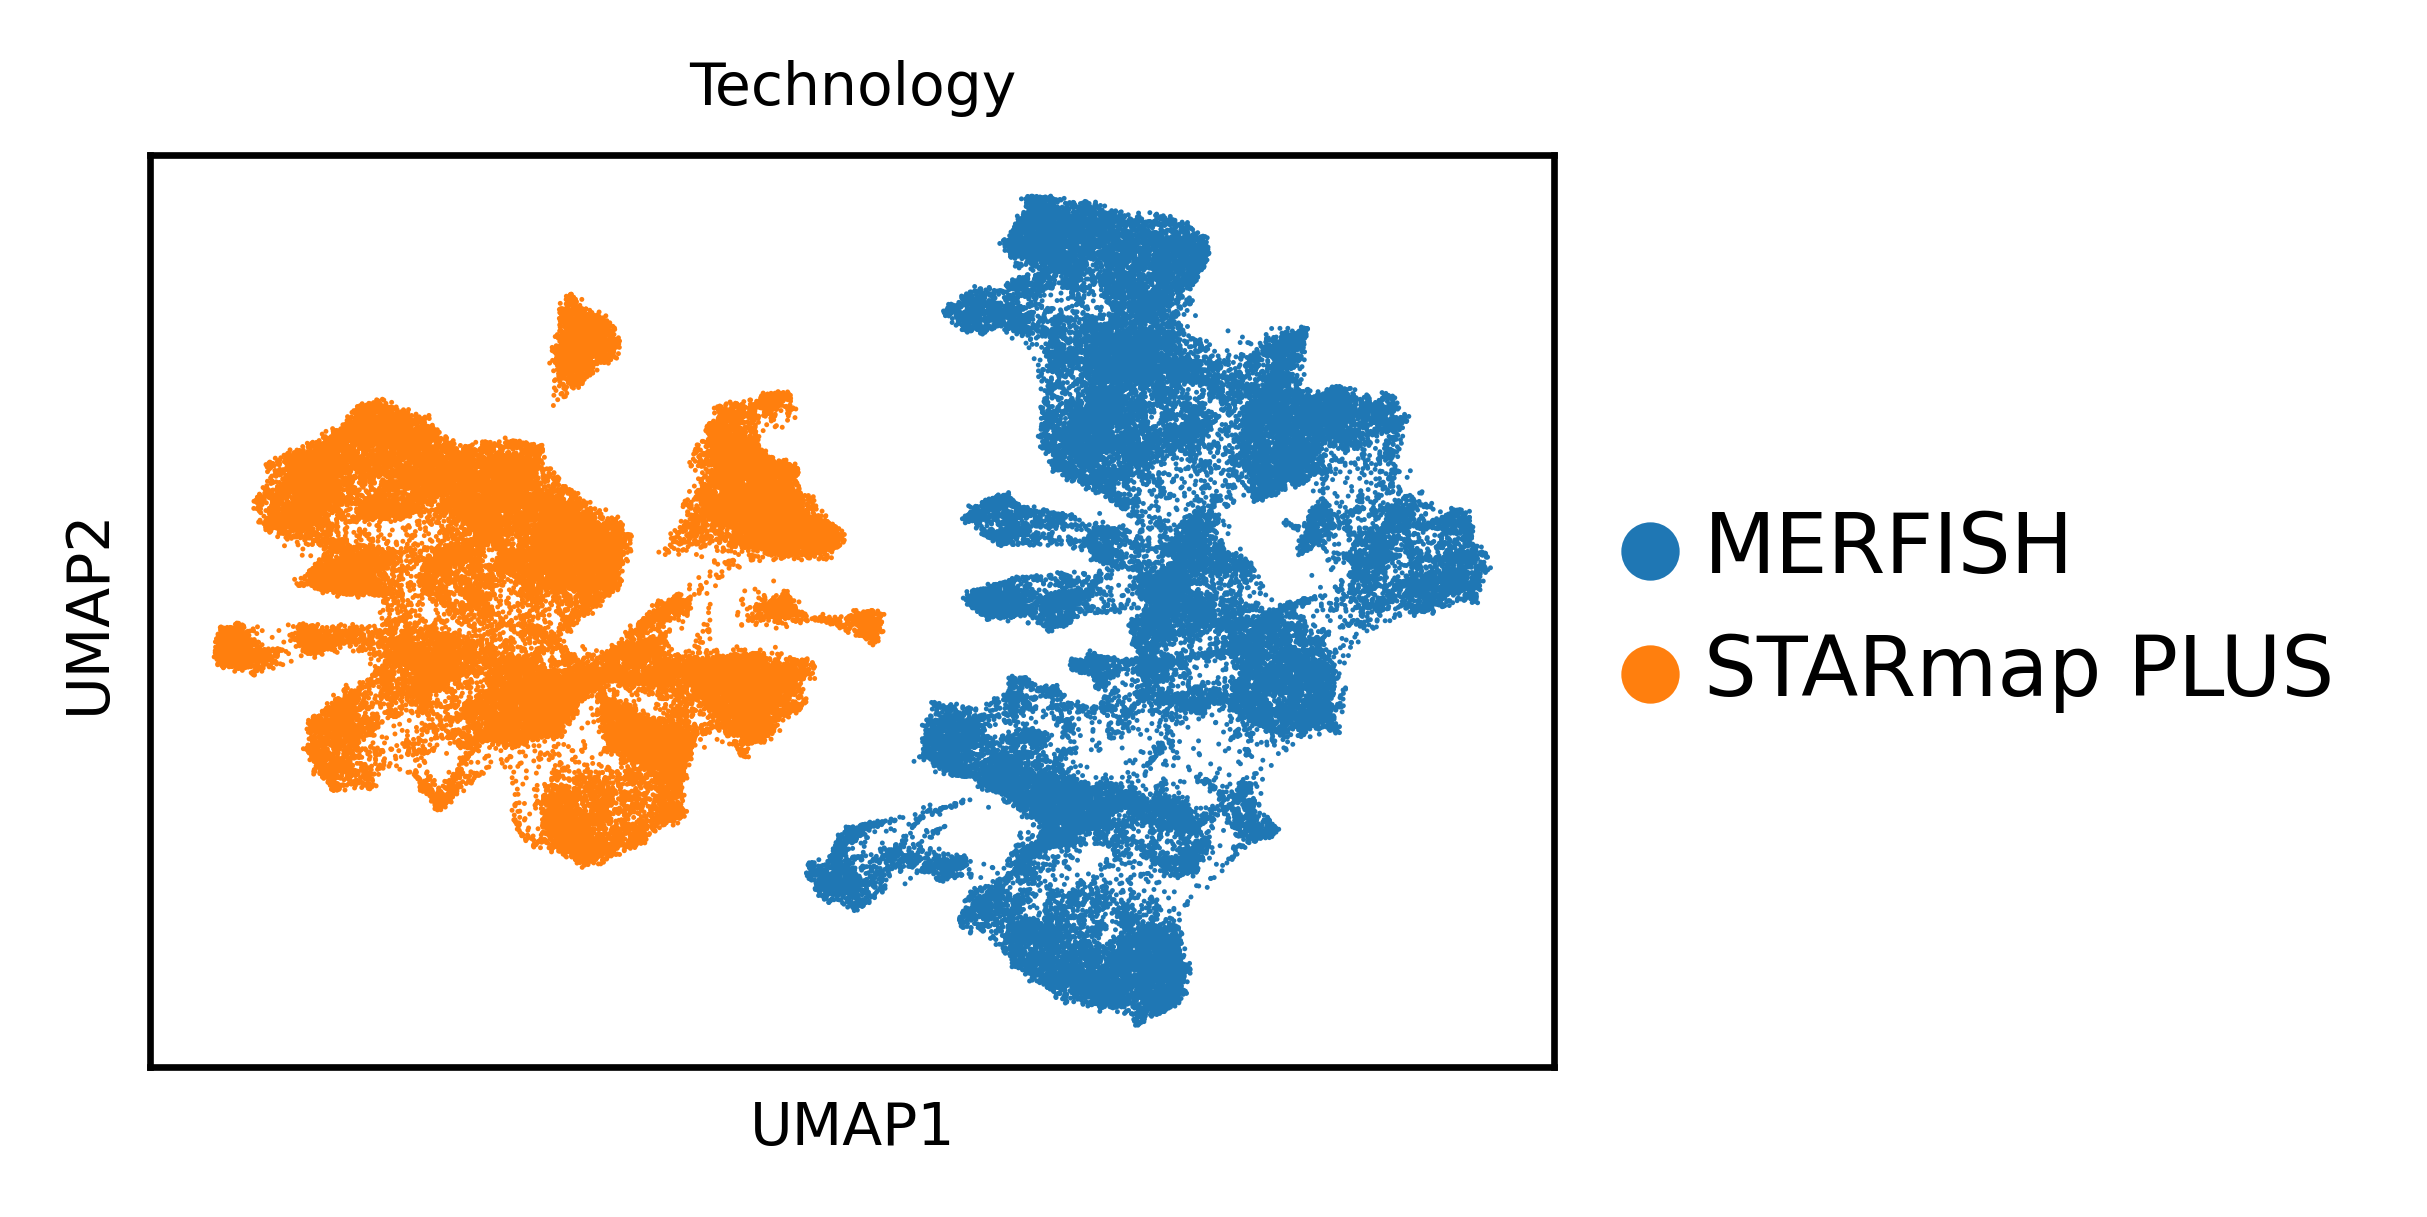

/tmp/ipykernel_3504031/3447051690.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"


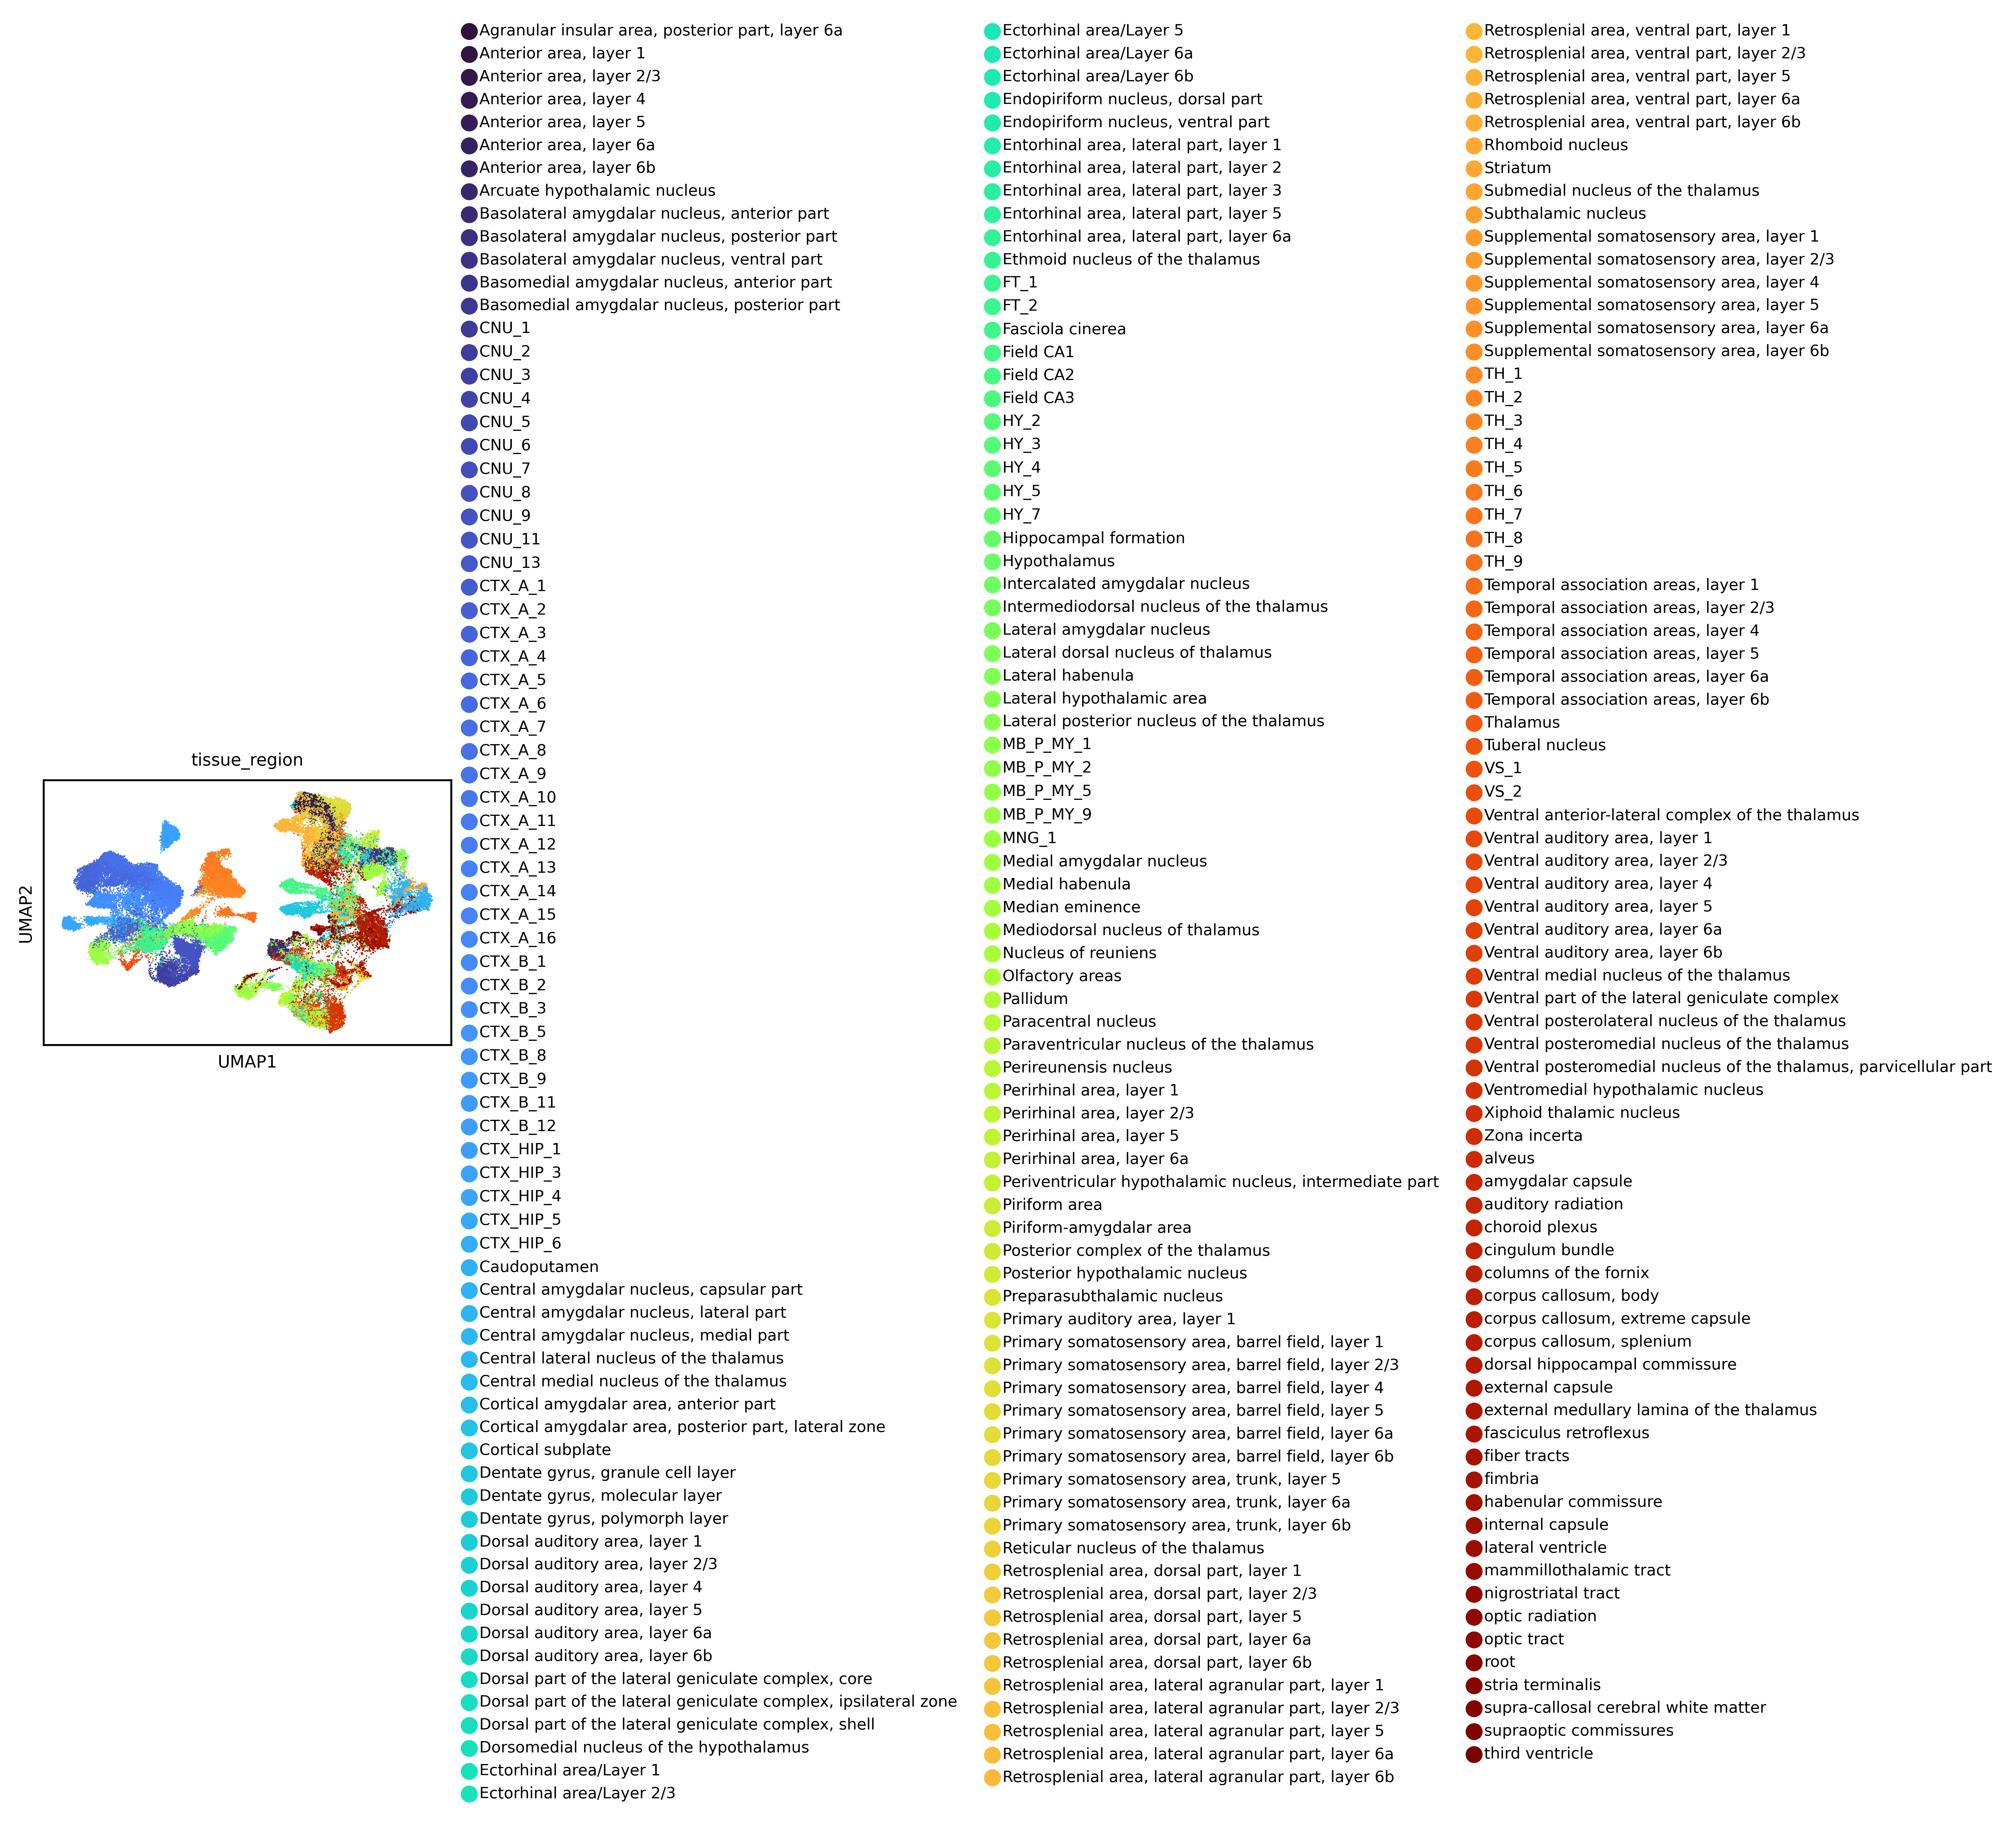

In [27]:
# Plot neighborhood-level expression-based UMAP
adata.layers["X_neigh"] = (
    adata.obsp["spatial_connectivities"].T @ adata.X)

# Log-normalize counts
#adata.layers["X_neigh_counts"] = adata.layers["X_neigh"].copy()
sc.pp.normalize_total(adata, target_sum=1e4, layer="X_neigh")
sc.pp.log1p(adata, layer="X_neigh")

try: # if rapids_singlecell is installed
    sc.pp.pca(adata, # not enough GPU memory
              layer="X_neigh",
              n_comps=n_pca_pcs)
    
    rsc.pp.neighbors(adata,
        n_neighbors=15,
        use_rep=emb_key,
        n_pcs=None,
        key_added="expr_neigh")

    rsc.tl.umap(adata,
                neighbors_key="expr_neigh",
                key_added="expr_neigh_umap")
except NameError:
    sc.pp.pca(adata,
              layer="X_neigh",
              n_comps=n_pca_pcs)

    sc.pp.neighbors(adata,
                    n_neighbors=15,
                    use_rep=emb_key,
                    n_pcs=None,
                    key_added="expr_neigh")

    sc.tl.umap(adata,
               neighbors_key="expr_neigh",
               key_added="expr_neigh_umap")


adata.obsm["X_umap"] = adata.obsm["expr_neigh_umap"]

n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
adata.obs[batch_key] = adata.obs[batch_key].astype("category")
categories = adata.obs[batch_key].cat.categories.tolist()
assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

sc.pl.umap(
    adata,
    color=batch_key,
    title="Technology",
    legend_loc="right margin",
    legend_fontsize=10,
    show=False,
)
for collection in plt.gca().collections:
    collection.set_rasterized(True)
plt.savefig(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
    format="svg", bbox_inches="tight"
)
plt.show()
plt.close()

for label_key in label_keys:
    n_cats = adata.obs[label_key].nunique()
    palette = make_large_cmap(n_cats)
    sc.pl.umap(adata, color=label_key, palette=palette, show=False)
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [28]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.3 Visualize Niches

In [46]:
# Plot neighborhood-level expression-based clusters
latent_cluster_key = f"{method}_clusters_res_{latent_leiden_resolution}"

try:
    rsc.tl.leiden(adata,
                  neighbors_key='expr_neigh',
                  key_added=latent_cluster_key,
                  resolution=latent_leiden_resolution,
                  flavor="igraph",
                  n_iterations=2)
except NameError:
    sc.tl.leiden(adata,
                 neighbors_key='expr_neigh',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution,
                 flavor="igraph",
                 n_iterations=2)

In [51]:
print(adata.obs[latent_cluster_key].nunique())
print(adata.obs[latent_cluster_key].value_counts())

30
neigh_expr_pca_clusters_res_0.7
19    6939
5     6598
1     5621
27    5549
11    5135
23    5082
3     4838
4     4601
0     3903
20    3862
25    3610
24    3211
7     3010
2     2939
17    2701
15    2397
21    2346
18    1614
14    1584
16    1484
12    1424
28    1417
6     1076
8      953
10     853
26     810
29     773
9      540
13     491
22     343
Name: count, dtype: int64


In [54]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded_clustered.h5ad')

/tmp/ipykernel_3504031/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/nichecompass/lib/python3.12/site-packages/scanpy/plotting/_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


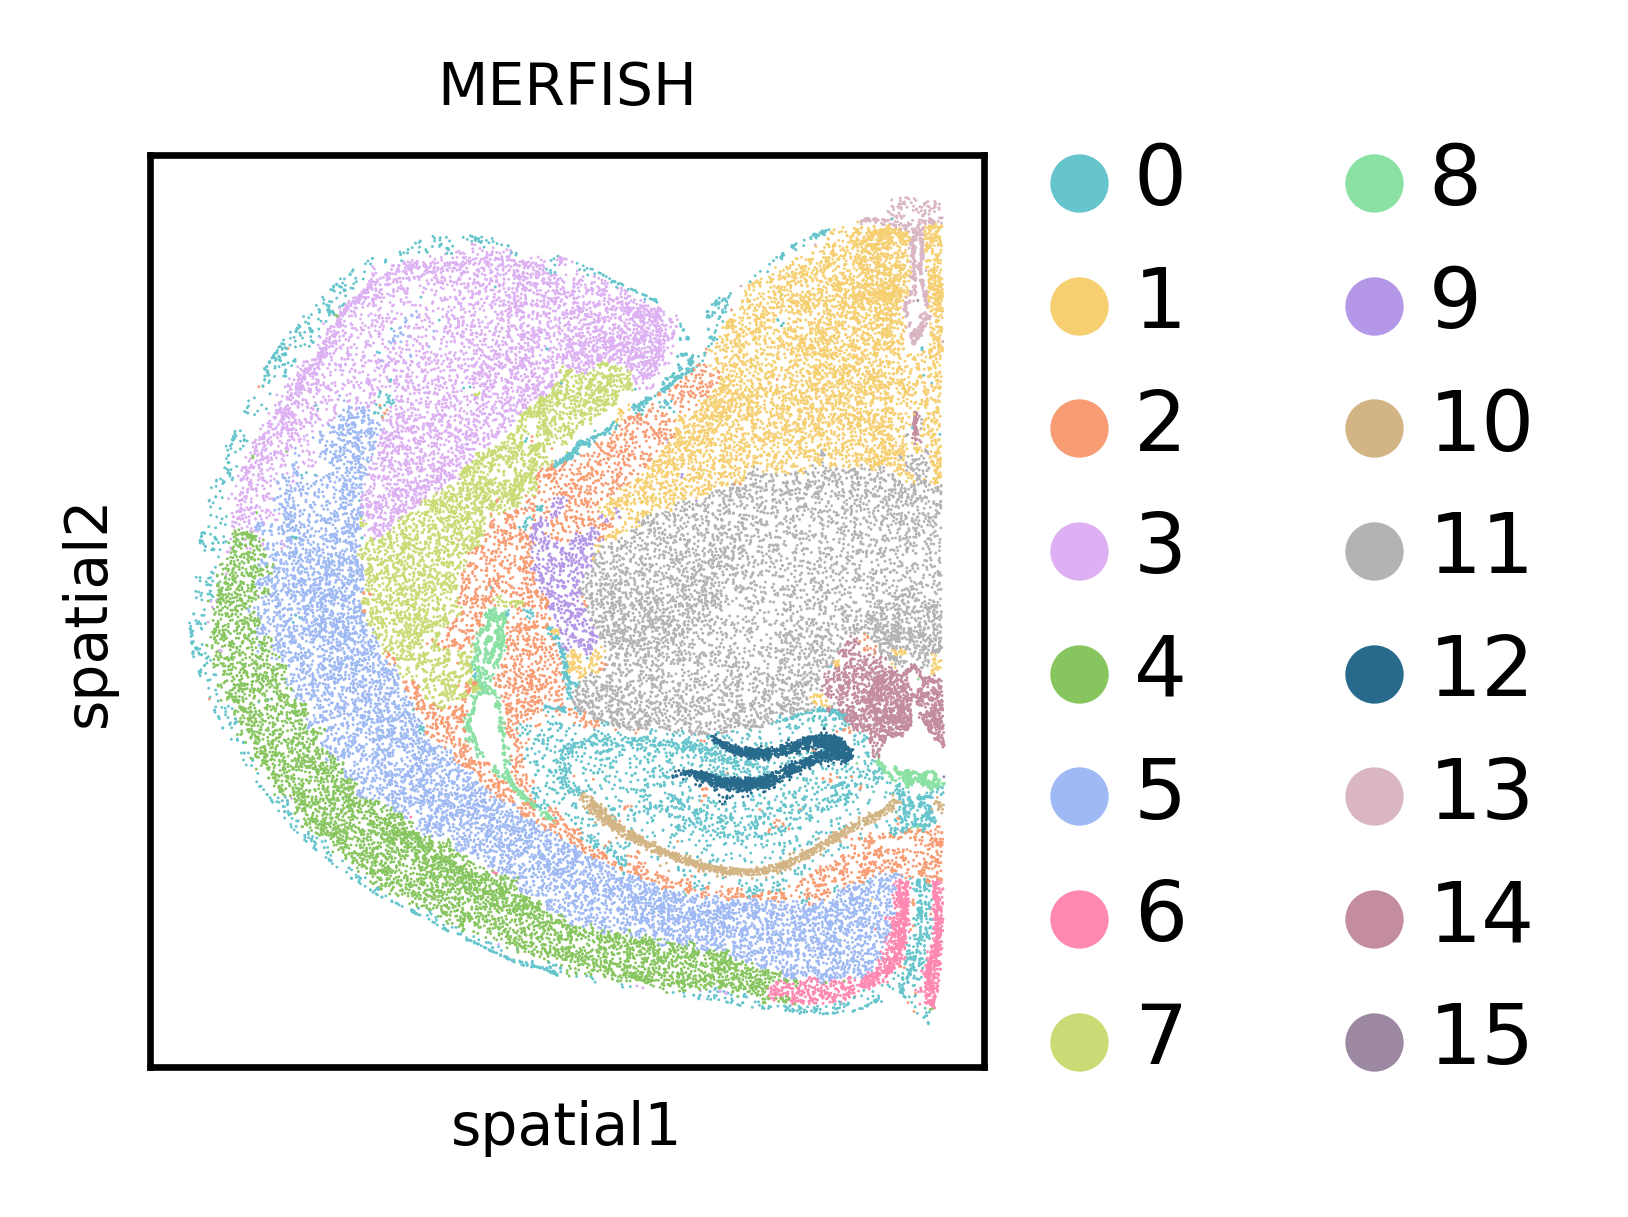

/tmp/ipykernel_3504031/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/nichecompass/lib/python3.12/site-packages/scanpy/plotting/_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


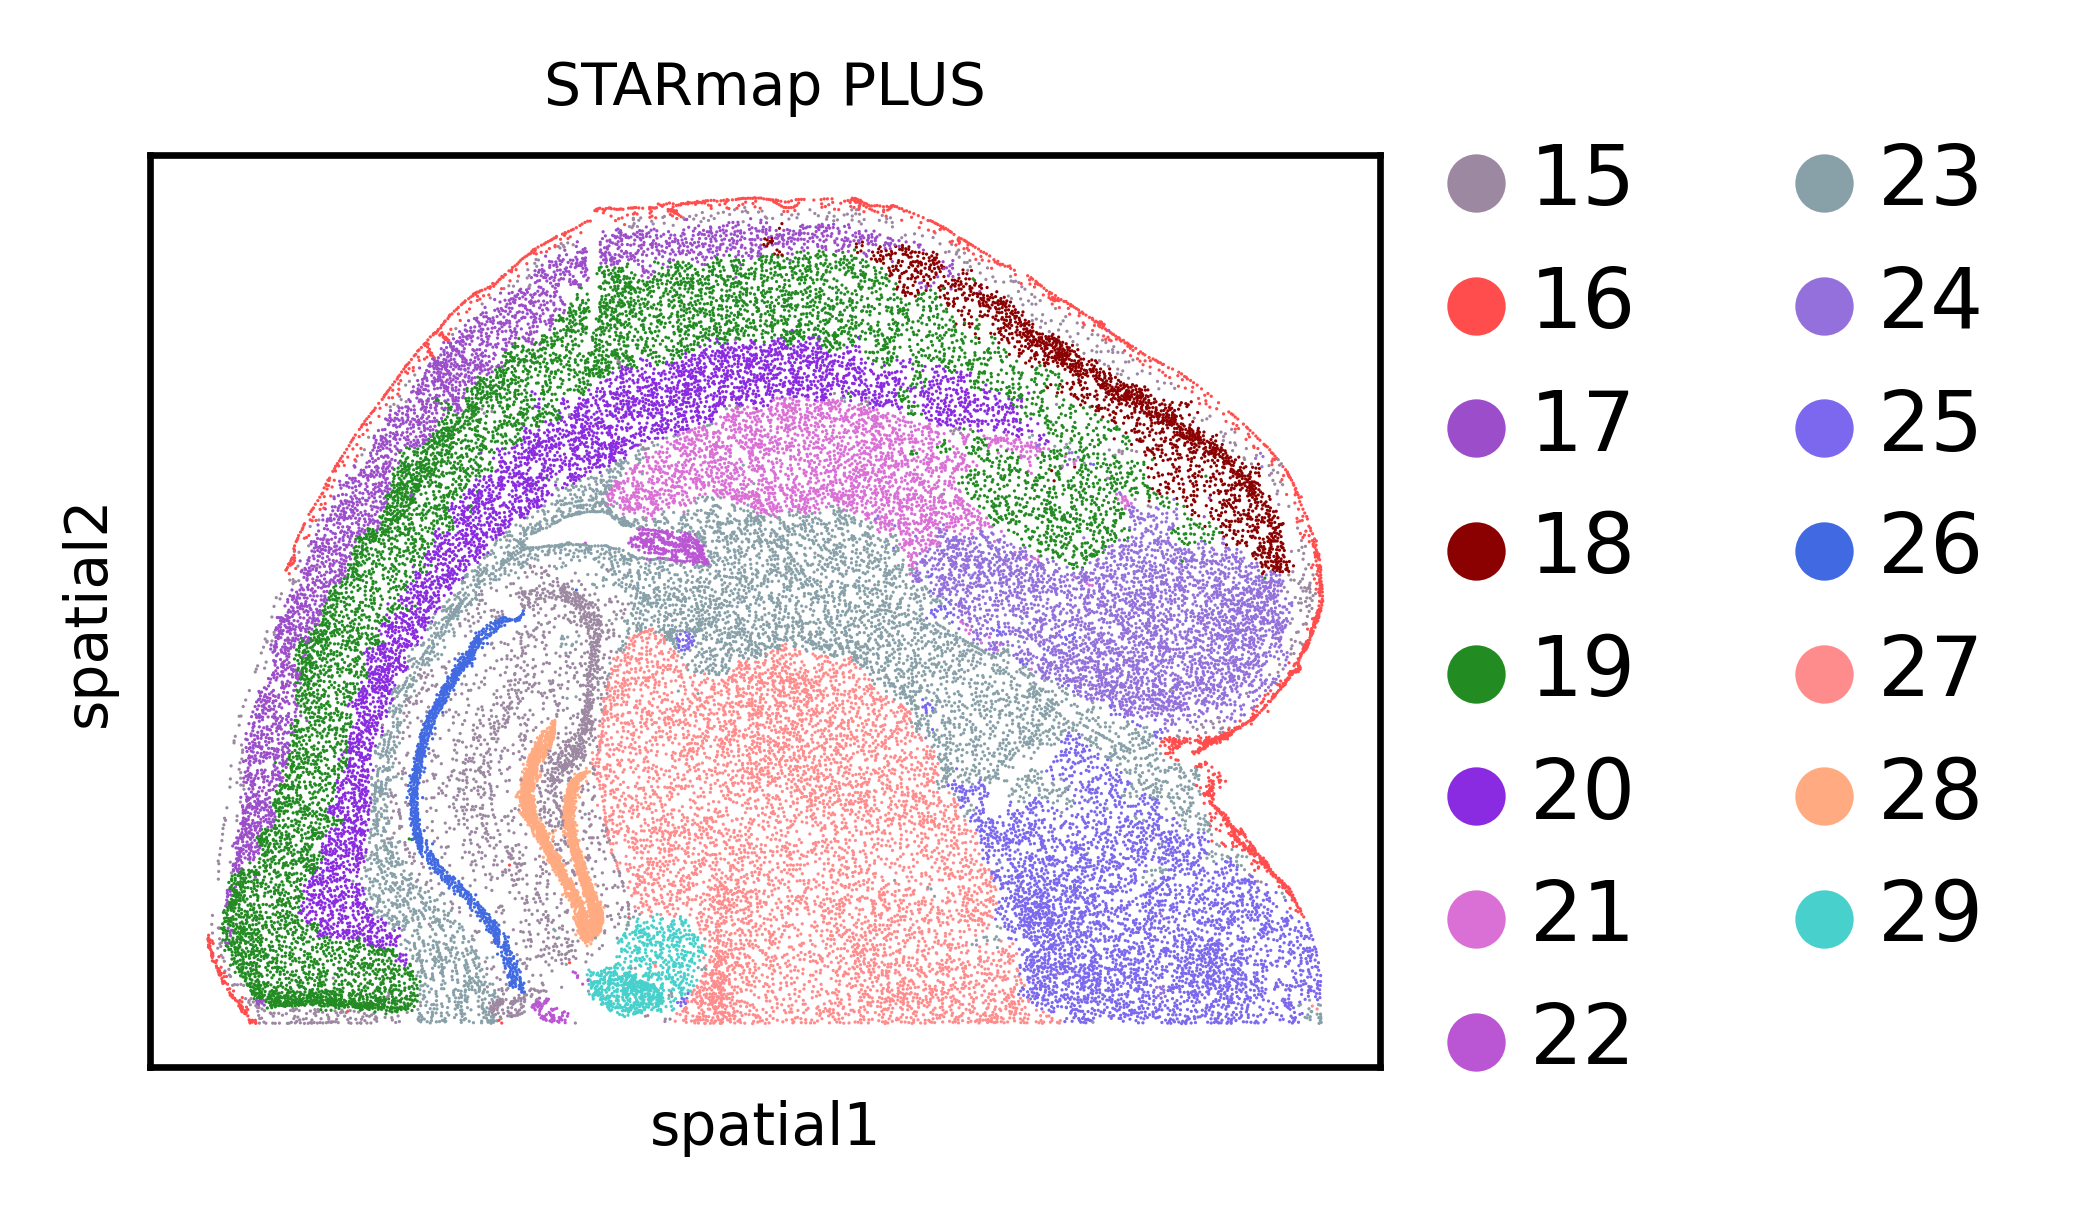

In [63]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

### 2.4 Compute Metrics

In [65]:
# Compute average cosine similarity of embeddings
X = adata.obsm[emb_key]
X = X / np.linalg.norm(X, axis=1, keepdims=True)
n = X.shape[0]
S = X.sum(axis=0)
avg_cos_sim = (S @ S - n) / (n * (n - 1))
print(f'{emb_key} average cosine similarity: {avg_cos_sim}')

cos_sim_result = pd.DataFrame([{
    "emb_key": emb_key,
    "avg_cosine_similarity": avg_cos_sim,
}])

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_avg_cosine_similarity.csv"
)
cos_sim_result.to_csv(out_path, index=False)
print(f"Saved → {out_path}")

X_pca average cosine similarity: 0.0022114324383437634
Saved → /nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/neigh_expr_pca/mmb0-1b_smb1-1b_1p_X_pca_avg_cosine_similarity.csv


In [49]:
# Compute NMI and ARI with region annotations
results = []
for region_key in ["Sub_molecular_tissue_region", "ccf_region_name"]:
    mask = adata.obs[region_key].notna()
    labels_true = adata.obs.loc[mask, region_key]
    labels_pred = adata.obs.loc[mask, latent_cluster_key]
    nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
    ari = skm.adjusted_rand_score(labels_true, labels_pred)
    print(f"NMI ({region_key}): {nmi:.4f}")
    print(f"ARI ({region_key}): {ari:.4f}")
    results.append({"region_key": region_key, "NMI": nmi, "ARI": ari})

df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{latent_cluster_key}_niche_identification_metrics.csv",
    index=False
)

NMI (Sub_molecular_tissue_region): 0.6917
ARI (Sub_molecular_tissue_region): 0.3846
NMI (ccf_region_name): 0.5688
ARI (ccf_region_name): 0.1598


In [71]:
# Compute batch integration metrics
results = []

# iLISI
batch = adata.obs[batch_key].values
knn = pynndescent(adata.obsm[emb_key], n_neighbors=90)
ilisi = float(np.mean(ilisi_knn(knn, batch)))
print(f"iLISI: {ilisi:.4f}")
results.append({"metric": "iLISI", "score": ilisi})

# ASW
asw = silhouette_score(
    adata.obsm[emb_key],
    adata.obs["batch"],
    metric="euclidean",
    sample_size=10000
)
print(f"ASW batch: {asw:.4f}")
results.append({"metric": "ASW", "score": asw})

# MMD
mmd_score = mmd_comparable(adata, emb_key, batch_key)
print(f"MMD: {mmd_score:.4f}")
results.append({"metric": "MMD", "score": mmd_score})

# Save
df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_batch_integration_metrics.csv",
    index=False
)

iLISI: 0.0000
ASW batch: 0.2667
MMD: 0.0721


In [64]:
# --- Config -----------------------------------------------------------
N_STEPS   = 4      # points above and below base resolution
STEP_SIZE = 0.1
MIN_RES   = 0.1    # Leiden resolution must be > 0

region_keys = ["Sub_molecular_tissue_region", "ccf_region_name"]

# Build resolution grid: N_STEPS below and above base, clamped to MIN_RES
# Use integer steps to avoid float accumulation errors in np.arange
base_int = round(latent_leiden_resolution / STEP_SIZE)  # e.g. 1.0/0.1 -> 10
resolutions = [
    round(step * STEP_SIZE, 1)
    for step in range(base_int - N_STEPS, base_int + N_STEPS + 1)
    if step * STEP_SIZE >= MIN_RES
]

# --- Sweep ------------------------------------------------------------
all_results = []

for res in resolutions:
    cluster_key = f"{emb_key}_clusters_res_{res}"

    # Leiden clustering
    try:
        rsc.tl.leiden(adata,
                      neighbors_key='expr_neigh',
                      key_added=cluster_key,
                      resolution=res,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key='expr_neigh',
                     key_added=cluster_key,
                     resolution=res,
                     flavor="igraph",
                     n_iterations=2)

    n_clusters = adata.obs[cluster_key].nunique()
    print(f"\n── Resolution {res:.1f}  ({n_clusters} clusters) ──")

    for region_key in region_keys:
        mask        = adata.obs[region_key].notna()
        labels_true = adata.obs.loc[mask, region_key]
        labels_pred = adata.obs.loc[mask, cluster_key]

        nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
        ari = skm.adjusted_rand_score(labels_true, labels_pred)
        print(f"  {region_key:40s}  NMI={nmi:.4f}  ARI={ari:.4f}")

        all_results.append({
            "resolution": res,
            "n_clusters": n_clusters,
            "region_key": region_key,
            "NMI":        nmi,
            "ARI":        ari,
        })

# --- Save -------------------------------------------------------------
df = pd.DataFrame(all_results)

# Canonical column order
df = df[["resolution", "n_clusters", "region_key", "NMI", "ARI"]]

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_niche_identification_metrics_res_sweep.csv"
)
df.to_csv(out_path, index=False)
print(f"\nSaved {len(df)} rows → {out_path}")


── Resolution 0.3  (19 clusters) ──
  Sub_molecular_tissue_region               NMI=0.5798  ARI=0.1842
  ccf_region_name                           NMI=0.5299  ARI=0.1279

── Resolution 0.4  (20 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6153  ARI=0.2542
  ccf_region_name                           NMI=0.5344  ARI=0.1293

── Resolution 0.5  (25 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6517  ARI=0.3081
  ccf_region_name                           NMI=0.5629  ARI=0.1497

── Resolution 0.6  (28 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6608  ARI=0.3211
  ccf_region_name                           NMI=0.5737  ARI=0.1626

── Resolution 0.7  (30 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6917  ARI=0.3846
  ccf_region_name                           NMI=0.5688  ARI=0.1598

── Resolution 0.8  (31 clusters) ──
  Sub_molecular_tissue_region               NMI=0.7002  ARI=0.4057
  ccf_region_name                        